# Stage 4: pricing tools and an evaluation framework

Stages 1-3 left two problems open: every calculation was the model's own arithmetic, and each stage was judged on a handful of products. This stage gives the pricing agent **three calculation tools** and builds an **evaluation framework** to measure it:

- **Answer quality:** pass/fail checks for accuracy, completeness and clarity, from an LLM judge, plus a code check of the price.
- **Tool use:** precision, recall, success rate and efficiency.
- **A comparison of three agent versions** that differ only in their system prompt.
- **Cost and execution time.**

**How the evaluation is set up**

- **Model:** the three agents and the judge all use `gpt-oss-120b`, on Cerebras when `CEREBRAS_API_KEY` is set in `.env` and on Groq (`openai/gpt-oss-120b`) otherwise.
- **Tools:** stage 3 retrieves evidence but has no tools, so section 1 defines three pricing tools with simple, documented formulas.
- **Only the system prompt differs between the three agents** (same model, same tools, same settings), so differences in the scores come from the prompt.
- **Accuracy is checked twice:** the LLM judge scores it, and plain code also checks the price in the answer against the expected range. Section 4b tests the judge on hand-labelled answers before it is used, and section 7b compares the judge with the code on every real answer.
- **Every question runs 3 times per agent**, because answers vary from run to run.

## Setup

Install the dependencies from the repository root (`pip install -r requirements.txt`) and put your API key in a `.env` file at the repository root (copy `.env.example`).

In [1]:
# Import required libraries
from langchain_groq import ChatGroq
from langchain_core.prompts import PromptTemplate
from langchain_core.messages import SystemMessage, HumanMessage, ToolMessage
from langchain_core.tools import tool
import os
import getpass
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import json
import re
import time
from typing import List, Dict, Optional, Tuple
from dataclasses import dataclass, field

In [2]:
# Set up your API key
# Uses keys from the environment or the project's .env file, and only asks if none is found.
# With CEREBRAS_API_KEY set, the agents and the judge run on Cerebras (the same open model as on Groq,
# with much higher rate limits); otherwise they run on Groq's free tier.
from dotenv import load_dotenv

load_dotenv()
if os.environ.get("CEREBRAS_API_KEY"):
    PROVIDER, MODEL = "Cerebras", "gpt-oss-120b"
else:
    PROVIDER, MODEL = "Groq", "openai/gpt-oss-120b"
    if not os.environ.get("GROQ_API_KEY"):
        print("Please enter your Groq API key:")
        print("(You can get one free at: https://console.groq.com/)")
        os.environ["GROQ_API_KEY"] = getpass.getpass("Groq API Key: ")


def make_llm(temperature: float, max_tokens: int = 4096):
    """The chat model used by the agents and the judge (Cerebras if its key is set, else Groq).

    max_tokens: gpt-oss also spends tokens on hidden reasoning; without a limit Groq can cut a reply off.
    max_retries: wait and retry when a tokens-per-minute limit is hit, instead of failing the run.
    """
    if PROVIDER == "Cerebras":
        from langchain_openai import ChatOpenAI
        return ChatOpenAI(model=MODEL, base_url="https://api.cerebras.ai/v1",
                          api_key=os.environ["CEREBRAS_API_KEY"],
                          temperature=temperature, max_tokens=max_tokens, max_retries=10)
    return ChatGroq(model=MODEL, temperature=temperature, max_tokens=max_tokens, max_retries=10)


print(f"API key configured! Using {PROVIDER}: {MODEL}")

API key configured! Using Cerebras: gpt-oss-120b


## 1. Pricing tools

Three tools that do the arithmetic the earlier stages left to the model.

In [3]:
# Stage 3 retrieves evidence but has no tools, so the three pricing tools are defined here. Each tool
# checks its inputs and returns a
# dict. Bad input returns {"error": ...} instead of raising, so the agent can read what went wrong and
# the evaluation can count it as a failed tool call.

# Business assumptions (illustrative numbers, not market data)
ELASTICITY_COEFFICIENTS = {   # % change in units sold for a +1% change in price
    "elastic": -2.0,          # easy to compare and substitute (e.g. phone accessories)
    "unit": -1.0,             # unit elastic: small price moves barely change revenue
    "inelastic": -0.5,        # few substitutes (e.g. printer ink)
}
ELASTICITY_ALIASES = {"high": "elastic", "highly elastic": "elastic", "low": "inelastic",
                      "unitary": "unit", "unit elastic": "unit", "unit-elastic": "unit"}
POSITIONING_OFFSETS = {"match": 0.0, "undercut": -5.0, "premium": 10.0}  # % vs the competitor's price
MIN_MARGIN_PERCENT = 10.0     # competitor_matching never recommends less than a 10% margin


def _as_percent(value: float) -> float:
    """Read 25 or 0.25 as 25% (a margin under 1% is unrealistic, so values below 1 are fractions)."""
    value = float(value)
    return value * 100 if 0 < value < 1 else value


@tool
def margin_calculator(cost_price: float, target_margin: float) -> dict:
    """Calculate optimal selling price based on cost and target margin.

    Args:
        cost_price: what one unit costs us, in dollars.
        target_margin: profit margin as a percent of the selling price (25 means 25%).
    """
    margin = _as_percent(target_margin)
    if cost_price <= 0:
        return {"error": "cost_price must be greater than 0"}
    if not 0 <= margin < 100:
        return {"error": f"target_margin must be at least 0% and below 100% (got {margin}%): "
                         "a margin is a share of the selling price"}
    price = cost_price / (1 - margin / 100)
    return {
        "cost_price": round(cost_price, 2),
        "target_margin_percent": round(margin, 2),
        "selling_price": round(price, 2),
        "profit_per_unit": round(price - cost_price, 2),
        "markup_percent": round((price - cost_price) / cost_price * 100, 2),
    }


@tool
def elasticity_adjustment(base_price: float, elasticity: str, price_change_percent: float) -> dict:
    """Adjust pricing based on demand elasticity to optimize revenue.

    Estimates how a price change affects units sold and revenue, and recommends whether to make it.

    Args:
        base_price: current price, in dollars.
        elasticity: "elastic", "unit" or "inelastic" (or a coefficient such as "-1.8").
        price_change_percent: the proposed change in percent (10 = raise 10%, -5 = cut 5%).
    """
    key = str(elasticity).strip().lower()
    key = ELASTICITY_ALIASES.get(key, key)
    if key in ELASTICITY_COEFFICIENTS:
        coefficient = ELASTICITY_COEFFICIENTS[key]
    else:
        try:
            coefficient = -abs(float(key))
        except ValueError:
            return {"error": f"unknown elasticity '{elasticity}': use elastic, unit, inelastic or a number"}
    if base_price <= 0:
        return {"error": "base_price must be greater than 0"}
    if price_change_percent <= -100:
        return {"error": "price_change_percent must be greater than -100"}
    new_price = base_price * (1 + price_change_percent / 100)
    demand_change = coefficient * price_change_percent
    revenue_change = ((1 + price_change_percent / 100) * (1 + demand_change / 100) - 1) * 100
    worth_it = revenue_change > 0
    return {
        "base_price": round(base_price, 2),
        "elasticity_coefficient": coefficient,
        "proposed_price": round(new_price, 2),
        "expected_demand_change_percent": round(demand_change, 2),
        "expected_revenue_change_percent": round(revenue_change, 2),
        "recommendation": "make the change" if worth_it else "keep the current price",
        "recommended_price": round(new_price if worth_it else base_price, 2),
    }


@tool
def competitor_matching(our_cost: float, competitor_price: float, positioning: str = "match") -> dict:
    """Calculate optimal pricing relative to competitor prices.

    Args:
        our_cost: what one unit costs us, in dollars.
        competitor_price: the competitor's price for a comparable product, in dollars.
        positioning: "match" (same price), "undercut" (5% below) or "premium" (10% above).
    """
    pos = str(positioning).strip().lower()
    if pos not in POSITIONING_OFFSETS:
        return {"error": f"unknown positioning '{positioning}': use match, undercut or premium"}
    if our_cost <= 0 or competitor_price <= 0:
        return {"error": "our_cost and competitor_price must be greater than 0"}
    target = competitor_price * (1 + POSITIONING_OFFSETS[pos] / 100)
    floor = our_cost / (1 - MIN_MARGIN_PERCENT / 100)
    price = max(target, floor)
    result = {
        "positioning": pos,
        "competitor_price": round(competitor_price, 2),
        "target_price": round(target, 2),
        "minimum_price": round(floor, 2),
        "recommended_price": round(price, 2),
        "margin_percent": round((price - our_cost) / price * 100, 2),
        "floor_applied": target < floor,
    }
    if target < floor:
        result["warning"] = (f"'{pos}' would mean ${target:.2f}, below our minimum price ${floor:.2f} "
                             f"(a {MIN_MARGIN_PERCENT:.0f}% margin), so the minimum price is recommended")
    return result


# List of pricing tools
pricing_tools = [margin_calculator, elasticity_adjustment, competitor_matching]
print(f"Imported {len(pricing_tools)} pricing tools: {', '.join(t.name for t in pricing_tools)}\n")

# Each tool on its own (no LLM involved)
print(margin_calculator.invoke({"cost_price": 100, "target_margin": 25}))
print(elasticity_adjustment.invoke({"base_price": 50, "elasticity": "elastic", "price_change_percent": 10}))
print(competitor_matching.invoke({"our_cost": 12, "competitor_price": 11, "positioning": "undercut"}))

Imported 3 pricing tools: margin_calculator, elasticity_adjustment, competitor_matching

{'cost_price': 100.0, 'target_margin_percent': 25.0, 'selling_price': 133.33, 'profit_per_unit': 33.33, 'markup_percent': 33.33}
{'base_price': 50.0, 'elasticity_coefficient': -2.0, 'proposed_price': 55.0, 'expected_demand_change_percent': -20.0, 'expected_revenue_change_percent': -12.0, 'recommendation': 'keep the current price', 'recommended_price': 50.0}
{'positioning': 'undercut', 'competitor_price': 11.0, 'target_price': 10.45, 'minimum_price': 13.33, 'recommended_price': 13.33, 'margin_percent': 10.0, 'floor_applied': True, 'warning': "'undercut' would mean $10.45, below our minimum price $13.33 (a 10% margin), so the minimum price is recommended"}


## 2. Three agent versions

Same model, tools and settings; only the system prompt changes: a one-line **basic** prompt, a **structured** prompt with a three-step process, and a **comprehensive** prompt with the tool list, an analysis process, business checks and a fixed final line.

In [4]:
class PricingAgent:
    def __init__(self, prompt_version: str):
        # Same model, tools and settings for every version: only the system prompt changes
        self.llm = make_llm(temperature=0.1)
        self.tools = pricing_tools
        self.tools_by_name = {t.name: t for t in self.tools}
        self.llm_with_tools = self.llm.bind_tools(self.tools)

        self.prompt_version = prompt_version
        self.system_message = self._get_system_prompt(prompt_version)

    def _get_system_prompt(self, version: str) -> SystemMessage:
        prompts = {
            "basic": "You are a pricing assistant. Answer the user's pricing question.",

            "structured": """You are a retail pricing analyst.

Process:
1. Identify what the user wants to know and every number they give (cost, margin target, competitor price, demand elasticity, proposed price change).
2. Use the pricing tools for the calculations instead of doing the arithmetic yourself.
3. Recommend one final price and explain it in 2-4 sentences.""",

            "comprehensive": """You are a senior retail pricing strategist with 15 years of experience in margin management, competitive positioning and demand analysis.

Available tools:
- margin_calculator(cost_price, target_margin): the selling price that gives a target margin (margin = share of the selling price; 25 means 25%).
- competitor_matching(our_cost, competitor_price, positioning): a price that matches, undercuts (5% below) or sits above (10% premium) a competitor's price, never below a 10% minimum margin.
- elasticity_adjustment(base_price, elasticity, price_change_percent): how a price change affects units sold and revenue for elastic, unit or inelastic demand, and whether to make the change.

How to analyse a request:
1. Extract every number and constraint: cost, margin target, competitor price, positioning, elasticity, proposed change, and the goal (margin, market share or revenue).
2. Call a tool for every calculation the question needs. Chain them when one result feeds the next step (for example, use the margin-based price as the base price of an elasticity check). Never calculate prices yourself.
3. Consider the business impact: the margin at your recommended price, how it compares with competitors, and the expected effect on units sold and revenue.
4. If a tool returns an error or a warning (such as a minimum-price floor), explain what it means for the decision instead of ignoring it.

Accuracy comes first: quote the tool results exactly and don't round prices to "nicer" numbers.

Answer in 3-6 short sentences or bullets, then end with one line exactly like:
Recommended price: $X.XX""",
        }
        return SystemMessage(content=prompts.get(version, prompts["basic"]))

    def calculate_price(self, query: str, max_steps: int = 6) -> dict:
        """Calculate price based on query and return response with metadata"""
        start = time.time()                                                   # 1. start time
        messages = [self.system_message, HumanMessage(content=query)]         # 2. system + human
        tool_calls = []
        usage = {"llm_calls": 0, "input_tokens": 0, "output_tokens": 0}

        def call_llm():                                                       # 3. LLM with tools
            ai_msg = self.llm_with_tools.invoke(messages)
            meta = ai_msg.usage_metadata or {}
            usage["llm_calls"] += 1
            usage["input_tokens"] += meta.get("input_tokens", 0)
            usage["output_tokens"] += meta.get("output_tokens", 0)  # includes hidden reasoning tokens
            messages.append(ai_msg)
            return ai_msg

        ai_msg = call_llm()
        steps = 0
        while ai_msg.tool_calls and steps < max_steps:                        # 4. tool-call loop
            steps += 1
            for tc in ai_msg.tool_calls:
                tool_fn = self.tools_by_name.get(tc["name"])
                if tool_fn is None:
                    result = {"error": f"unknown tool: {tc['name']}"}
                else:
                    try:
                        result = tool_fn.invoke(tc["args"])
                    except Exception as e:  # e.g. arguments that fail validation
                        result = {"error": f"{type(e).__name__}: {e}"}
                tool_calls.append({"tool": tc["name"], "args": tc["args"], "result": result})  # 5. track
                messages.append(ToolMessage(content=json.dumps(result), tool_call_id=tc["id"]))
            ai_msg = call_llm()

        return {                                                              # 6-7. time + results
            "response": "" if ai_msg.tool_calls else ai_msg.content,  # still calling tools = no answer
            "tool_calls": tool_calls,
            "execution_time": time.time() - start,
            "prompt_version": self.prompt_version,
            **usage,
        }


# Create agents with different prompts
agents = {
    "basic": PricingAgent("basic"),
    "structured": PricingAgent("structured"),
    "comprehensive": PricingAgent("comprehensive"),
}

print(f"Created {len(agents)} agent versions: {', '.join(agents)}")

Created 3 agent versions: basic, structured, comprehensive


In [5]:
# Quick check: the same question to each agent once, showing the tool calls and the answer
demo_query = "Calculate the selling price for a product with cost $100 and target margin 25%"
for name, agent in agents.items():
    run = agent.calculate_price(demo_query)
    print(f"=== {name}: {run['llm_calls']} LLM calls, {run['execution_time']:.1f}s")
    for call in run["tool_calls"]:
        print(f"  tool: {call['tool']}({call['args']}) -> {call['result']}")
    print(run["response"], "\n")

=== basic: 2 LLM calls, 1.1s
  tool: margin_calculator({'cost_price': 100, 'target_margin': 25}) -> {'cost_price': 100.0, 'target_margin_percent': 25.0, 'selling_price': 133.33, 'profit_per_unit': 33.33, 'markup_percent': 33.33}
The selling price that gives a **25 % profit margin** (margin = profit ÷ selling price) on a product that costs **$100** is:

**Selling price ≈ $133.33**

- **Profit per unit:** $33.33  
- **Markup over cost:** 33.33 % (since $33.33 ÷ $100)

So, price the product at about **$133.33** to achieve a 25 % margin. 

=== structured: 2 LLM calls, 0.9s
  tool: margin_calculator({'cost_price': 100, 'target_margin': 25}) -> {'cost_price': 100.0, 'target_margin_percent': 25.0, 'selling_price': 133.33, 'profit_per_unit': 33.33, 'markup_percent': 33.33}
The optimal selling price is **$133.33**. This price gives a 25 % profit margin on the $100 cost, yielding a $33.33 profit per unit. It balances the desired margin while keeping the price competitive enough to attract buyers

## 3. Evaluation dataset

Twelve questions: seven that need one tool, three that need several, and two edge cases.

In [6]:
# Evaluation dataset. Expected prices are worked out by hand from the tools' formulas (shown in the
# comments), not by calling the tools, so a bug in a tool would show up as a failure.
# Tool settings used: undercut = 5% below, premium = 10% above, minimum margin 10%,
# elasticity coefficients elastic -2.0 / unit -1.0 / inelastic -0.5.

evaluation_dataset = [
    # --- Single tool: margin ---
    {
        "id": 1,
        "query": "Calculate the selling price for a product with cost $100 and target margin 25%",
        "expected_tools": ["margin_calculator"],
        "expected_price_range": (130, 135),  # $100 / (1 - 0.25) = $133.33
        "category": "single_tool",
        "key_factors": ["margin", "cost"]
    },
    {
        "id": 2,
        "query": "We buy wireless earbuds at $45 per unit. What selling price gives us a 40% gross margin?",
        "expected_tools": ["margin_calculator"],
        "expected_price_range": (74.5, 75.5),  # $45 / (1 - 0.40) = $75.00
        "category": "single_tool",
        "key_factors": ["margin", "cost"]
    },
    # --- Single tool: competition ---
    {
        "id": 3,
        "query": "Our yoga mats cost us $18 each and the market leader sells a comparable mat for $32. "
                 "We want to match their price. What should we charge, and what margin does that give us?",
        "expected_tools": ["competitor_matching"],
        "expected_price_range": (31.5, 32.5),  # match = $32.00; margin (32 - 18) / 32 = 43.75%
        "category": "single_tool",
        "key_factors": ["competitor price", "margin"]
    },
    {
        "id": 4,
        "query": "A rival blender sells for $95. Our cost is $60 per unit and we want to undercut them "
                 "slightly to win market share. What price should we set?",
        "expected_tools": ["competitor_matching"],
        "expected_price_range": (89.5, 91.0),  # $95 x 0.95 = $90.25 (above the $66.67 floor)
        "category": "single_tool",
        "key_factors": ["competitor price", "undercutting"]
    },
    {
        "id": 5,
        "query": "Our premium coffee grinder costs us $70 to make and the main competitor's grinder sells "
                 "for $120. We position ourselves as the premium brand. What price do you recommend?",
        "expected_tools": ["competitor_matching"],
        "expected_price_range": (131, 133),  # $120 x 1.10 = $132.00
        "category": "single_tool",
        "key_factors": ["competitor price", "premium positioning"]
    },
    # --- Single tool: elasticity (different market conditions) ---
    {
        "id": 6,
        "query": "Our printer ink cartridges sell for $40 and demand is inelastic. What happens to revenue "
                 "if we raise the price by 10%, and what price do you recommend?",
        "expected_tools": ["elasticity_adjustment"],
        "expected_price_range": (43.5, 44.5),  # $44: units -5%, revenue 1.10 x 0.95 = +4.5% -> raise
        "category": "single_tool",
        "key_factors": ["inelastic demand", "revenue impact"]
    },
    {
        "id": 7,
        "query": "Our Bluetooth speaker sells for $50 and demand is elastic because shoppers compare prices "
                 "online. We're thinking of raising the price by 10%. Should we, and what price should we charge?",
        "expected_tools": ["elasticity_adjustment"],
        "expected_price_range": (49.5, 50.5),  # $55 would cut units 20%: revenue 1.10 x 0.80 = -12% -> keep $50
        "category": "single_tool",
        "key_factors": ["elastic demand", "revenue impact"]
    },
    # --- Multi tool ---
    {
        "id": 8,
        "query": "Our cost is $60 per unit. What is the lowest price that still gives us a 30% margin, and "
                 "can we match a competitor who sells at $90 instead? Recommend a final price.",
        "expected_tools": ["margin_calculator", "competitor_matching"],
        "expected_price_range": (89.5, 90.5),  # floor $60 / 0.70 = $85.71; matching $90 gives 33.3% -> $90
        "category": "multi_tool",
        "key_factors": ["margin target", "competitor price"]
    },
    {
        "id": 9,
        "query": "A desk lamp costs us $15 to make and we price it for a 70% margin. Demand for lamps is "
                 "elastic. Would a 10% price cut increase revenue, and what final price do you recommend?",
        "expected_tools": ["margin_calculator", "elasticity_adjustment"],
        "expected_price_range": (44.5, 45.5),  # $15 / 0.30 = $50; cut to $45: units +20%, revenue +8% -> $45
        "category": "multi_tool",
        "key_factors": ["margin", "elastic demand", "revenue impact"]
    },
    {
        "id": 10,
        "query": "Our smartwatch strap costs $20 per unit. The competitor charges $50, demand is elastic, and "
                 "we must keep at least a 35% margin. Compare our minimum margin price with matching the "
                 "competitor, then check whether cutting 5% below the competitor's price raises revenue. "
                 "What final price maximizes revenue while keeping the margin?",
        "expected_tools": ["margin_calculator", "competitor_matching", "elasticity_adjustment"],
        "expected_price_range": (47.0, 48.0),  # floor $20 / 0.65 = $30.77; match $50; cut 5% -> $47.50,
                                               # units +10%, revenue +4.5%, margin 57.9% -> $47.50
        "category": "multi_tool",
        "key_factors": ["margin target", "competitor price", "elastic demand", "revenue impact"]
    },
    # --- Edge cases ---
    {
        "id": 11,
        "query": "Our phone case costs us $12, but a competitor sells the same case for $11. We want to "
                 "undercut them. What price should we set?",
        "expected_tools": ["competitor_matching"],
        "expected_price_range": (13.2, 13.5),  # undercut = $10.45 < cost; floor $12 / 0.90 = $13.33
        "category": "edge_case",
        "key_factors": ["cost", "competitor price", "price floor"]
    },
    {
        "id": 12,
        "query": "Our cost is $80 and we want a target margin of 0.35. What should the selling price be?",
        "expected_tools": ["margin_calculator"],
        "expected_price_range": (122.5, 123.5),  # margin given as a fraction: $80 / 0.65 = $123.08
        "category": "edge_case",
        "key_factors": ["margin", "cost"]
    },
]
scenario_by_id = {s["id"]: s for s in evaluation_dataset}

print(f"Created {len(evaluation_dataset)} test scenarios")
print("By category:", pd.Series([s["category"] for s in evaluation_dataset]).value_counts().to_dict())

Created 12 test scenarios
By category: {'single_tool': 7, 'multi_tool': 3, 'edge_case': 2}


## 4. Answer-quality metrics

Binary checks from an LLM judge, plus a price check in code.

In [7]:
# The judge: same model as the agents, temperature 0 so the grading is repeatable. It never sees
# which agent wrote the answer (blind evaluation).
judge_llm = make_llm(temperature=0)

# The price check in code: find the price the answer recommends with simple rules, no LLM involved
PRICE_RE = re.compile(r"\$\s?(\d[\d,]*(?:\.\d+)?)")
RECOMMEND_RE = re.compile(r"recommend|suggest", re.IGNORECASE)
DECISION_RE = re.compile(r"final price|set (?:the |your )?price|charge|go with|keep (?:the |it |your )?(?:price )?at"
                         r"|price it at|selling price|new price", re.IGNORECASE)


def extract_final_price(response: str) -> Optional[float]:
    """Return the price the answer finally recommends, or None if it names no $ price.

    Looks at the lines with a $ amount: first lines that say "recommend"/"suggest", then lines with other
    decision words, then any line. On the last such line it takes the first $ amount after the word
    (or the last amount, when the line is a calculation like "= $133.33").
    """
    lines = [ln for ln in (response or "").splitlines() if PRICE_RE.search(ln)]
    if not lines:
        return None
    for pattern in (RECOMMEND_RE, DECISION_RE):
        hits = [ln for ln in lines if pattern.search(ln)]
        if hits:
            line = hits[-1]
            after = line[[m.end() for m in pattern.finditer(line)][-1]:]
            amounts = PRICE_RE.findall(after)
            if amounts:
                pick = amounts[-1] if "=" in after else amounts[0]
            else:
                pick = PRICE_RE.findall(line)[0]
            return float(pick.replace(",", ""))
    return float(PRICE_RE.findall(lines[-1])[-1].replace(",", ""))


def evaluate_prompt_response(query: str, response: str, expected_price_range: tuple,
                            key_factors: list, tool_calls: list) -> dict:
    """Evaluate response using binary metrics (0 or 1)"""
    # tool_calls is not used here: tool use is scored separately (section 5)

    eval_prompt = f"""You are a strict senior pricing analyst grading an AI pricing assistant. Grade the way
you would grade a junior analyst's answer to a customer: each criterion is pass (1) or fail (0), no partial credit.

Customer question:
{query}

Assistant's answer:
{response}

Reference (the assistant did not see this):
- Correct final price: between ${expected_price_range[0]} and ${expected_price_range[1]}
- Key factors the answer must address: {', '.join(key_factors)}

Criteria:
- Accuracy: 1 only if the price the answer finally recommends is inside the reference range. Intermediate
  figures don't count. 0 if the final recommendation is outside the range or there is no clear final price.
- Completeness: 1 only if the answer addresses EVERY key factor listed (in any wording); 0 if any is missing.
  Judge coverage here, not correctness (accuracy covers that).
- Clarity: 1 if a business owner could act on the answer without follow-up questions: one unambiguous
  final price, a short reason, no contradicting recommendations. 0 otherwise.

Respond ONLY:
Accuracy: X
Completeness: X
Clarity: X"""

    text = judge_llm.invoke(eval_prompt).content
    clean = text.replace("*", "")  # tolerate markdown like **Accuracy:** 1
    scores = {}
    for metric in ["Accuracy", "Completeness", "Clarity"]:
        found = re.findall(rf"{metric}\s*:\s*([01])", clean, re.IGNORECASE)
        scores[metric.lower()] = int(found[-1]) if found else 0
    scores["judge_parsed"] = all(re.search(rf"{m}\s*:\s*[01]", clean, re.IGNORECASE)
                                 for m in ["Accuracy", "Completeness", "Clarity"])

    # The code-based check: is the recommended price inside the expected range?
    price = extract_final_price(response)
    low, high = expected_price_range
    scores["extracted_price"] = price
    scores["price_in_range"] = int(price is not None and low <= price <= high)
    return scores


print("Judge and price check ready.")
print("Price check on a sample answer:", extract_final_price("A 10% rise to $55 would cut revenue.\nRecommendation: keep the price at $50."))

Judge and price check ready.
Price check on a sample answer: 50.0


### 4b. Validate the judge before trusting it

Never trust a judge you haven't tested. Below are 7 hand-written answers to questions 1 and 7, each labelled the way I would grade it. They include deliberately bad ones (wrong maths, no explanation, self-contradiction, falling for the elastic-demand trap), so that a judge that passes everything gets caught.

In [8]:
golden_set = [
    {"test_id": 1, "label": "correct and explained",
     "response": "Price it at $133.33. With a $100 cost and a 25% target margin, the price is $100 / (1 - 0.25) "
                 "= $133.33, which leaves $33.33 profit per unit: exactly 25% of the selling price.",
     "human": {"accuracy": 1, "completeness": 1, "clarity": 1}},
    {"test_id": 1, "label": "wrong maths (markup, not margin)",
     "response": "Your cost is $100 and you want a 25% margin, so add 25% to the cost and sell it at $125.",
     "human": {"accuracy": 0, "completeness": 1, "clarity": 1}},
    {"test_id": 1, "label": "right price, no explanation",
     "response": "$133.33.",
     "human": {"accuracy": 1, "completeness": 0, "clarity": 0}},
    {"test_id": 1, "label": "no single final price",
     "response": "The price should be $133.33 for a 25% margin on your $100 cost. I'd go with $129.99 or $135, "
                 "either works.",
     "human": {"accuracy": 0, "completeness": 1, "clarity": 0}},
    {"test_id": 7, "label": "falls for the elastic-demand trap",
     "response": "Yes, raise it. A 10% increase takes the speaker from $50 to $55, and the higher price per unit "
                 "will grow revenue even though demand is elastic. Charge $55.",
     "human": {"accuracy": 0, "completeness": 1, "clarity": 1}},
    {"test_id": 7, "label": "correct: keep the price",
     "response": "No. Demand is elastic, so a 10% increase to $55 would cut units sold by about 20% and revenue "
                 "by about 12%. Keep the price at $50.",
     "human": {"accuracy": 1, "completeness": 1, "clarity": 1}},
    {"test_id": 7, "label": "right price, reasoning missing",
     "response": "Keep it at $50.",
     "human": {"accuracy": 1, "completeness": 0, "clarity": 0}},
]

rows = []
for g in golden_set:
    s = scenario_by_id[g["test_id"]]
    judged = evaluate_prompt_response(s["query"], g["response"], s["expected_price_range"], s["key_factors"], [])
    for metric in ["accuracy", "completeness", "clarity"]:
        rows.append({"answer": f"Q{g['test_id']}: {g['label']}", "metric": metric,
                     "human": g["human"][metric], "judge": judged[metric]})
    rows.append({"answer": f"Q{g['test_id']}: {g['label']}", "metric": "price check (code)",
                 "human": g["human"]["accuracy"], "judge": judged["price_in_range"]})
golden_df = pd.DataFrame(rows)

print("Agreement with my labels:")
for metric, grp in golden_df.groupby("metric", sort=False):
    print(f"  {metric:<19} {(grp.human == grp.judge).sum()}/{len(grp)}")
llm_rows = golden_df[golden_df.metric != "price check (code)"]
print(f"  {'judge overall':<19} {(llm_rows.human == llm_rows.judge).sum()}/{len(llm_rows)} "
      f"({(llm_rows.human == llm_rows.judge).mean():.0%})")
false_pass = llm_rows[(llm_rows.human == 0) & (llm_rows.judge == 1)]
print(f"  false passes (I said fail, judge said pass): {len(false_pass)}")
mismatches = golden_df[golden_df.human != golden_df.judge]
print("\nDisagreements:" if len(mismatches) else "\nNo disagreements.")
if len(mismatches):
    print(mismatches.to_string(index=False))

Agreement with my labels:
  accuracy            7/7
  completeness        7/7
  clarity             7/7
  price check (code)  7/7
  judge overall       21/21 (100%)
  false passes (I said fail, judge said pass): 0

No disagreements.


## 5. Tool-use metrics

In [9]:
@dataclass
class ToolEvaluation:
    """Tool usage evaluation for a single test case"""
    query: str
    expected_tools: List[str]
    actual_tools: List[str]
    tool_precision: float     # calls that used an expected tool / all calls made
    tool_recall: float        # expected tools that were called at least once / expected tools
    tool_success_rate: float  # calls without an error / all calls made
    execution_time: float
    tool_count: int
    optimal_count: int

    @property
    def efficiency_classification(self) -> str:
        # Compare the number of calls with the minimum the question needs
        if self.tool_count < self.optimal_count:
            return "too_few"
        if self.tool_count == self.optimal_count:
            return "optimal"
        return "too_many"


def evaluate_tool_usage(expected_tools: List[str], tool_calls: List[dict],
                        query: str = "", execution_time: float = 0.0) -> ToolEvaluation:
    """Evaluate tool usage metrics"""
    actual_tools = [call["tool"] for call in tool_calls]
    expected = set(expected_tools)

    # Precision: of the calls made, the share that used an expected tool (a repeated call still counts)
    correct_calls = sum(1 for name in actual_tools if name in expected)
    precision = correct_calls / len(actual_tools) if actual_tools else (1.0 if not expected else 0.0)

    # Recall: of the expected tools, the share that was called at least once
    recall = len(expected & set(actual_tools)) / len(expected) if expected else (1.0 if not actual_tools else 0.0)

    # Success rate: of the calls made, the share that did not return an error
    ok_calls = sum(1 for call in tool_calls if not (isinstance(call["result"], dict) and "error" in call["result"]))
    success_rate = ok_calls / len(tool_calls) if tool_calls else 1.0

    return ToolEvaluation(
        query=query,
        expected_tools=expected_tools,
        actual_tools=actual_tools,
        tool_precision=precision,
        tool_recall=recall,
        tool_success_rate=success_rate,
        execution_time=execution_time,
        tool_count=len(actual_tools),
        optimal_count=len(expected_tools)
    )


# Example: margin_calculator expected; the agent called it twice, and the second call failed
example = evaluate_tool_usage(["margin_calculator"], [
    {"tool": "margin_calculator", "args": {}, "result": {"selling_price": 133.33}},
    {"tool": "margin_calculator", "args": {}, "result": {"error": "cost_price must be greater than 0"}},
])
print(f"precision={example.tool_precision}, recall={example.tool_recall}, "
      f"success rate={example.tool_success_rate}, efficiency={example.efficiency_classification}")

precision=1.0, recall=1.0, success rate=0.5, efficiency=too_many


## 6. Run the evaluation

Every agent answers every question 3 times, and every answer is judged.

In [10]:
N_TRIALS = 3  # every question runs 3 times per agent: answers vary from run to run, so one run can mislead
# 3 agents x 12 questions x 3 runs = 108 agent runs + 108 judge calls (roughly 0.5M tokens). Groq's free
# tier allows 200k tokens a day per model, so on Groq use N_TRIALS = 1 (and expect waits for rate limits).


def run_comprehensive_evaluation(agents: dict, dataset: list, n_trials: int = N_TRIALS) -> pd.DataFrame:
    """Run evaluation for all agents on all test cases"""

    results = []
    for agent_name, agent in agents.items():
        print(f"\n=== {agent_name} ===")
        for scenario in dataset:
            prices, judge_hits, tools_seen = [], [0, 0, 0], set()
            for trial in range(1, n_trials + 1):
                run = agent.calculate_price(scenario["query"])                        # 1. run the agent
                prompt_scores = evaluate_prompt_response(                              # 2. judge + price check
                    scenario["query"], run["response"], scenario["expected_price_range"],
                    scenario["key_factors"], run["tool_calls"])
                tool_eval = evaluate_tool_usage(scenario["expected_tools"], run["tool_calls"],  # 3. tool use
                                                scenario["query"], run["execution_time"])
                results.append({                                                       # 4-5. collect
                    "agent": agent_name,
                    "test_id": scenario["id"],
                    "trial": trial,
                    "category": scenario["category"],
                    "accuracy": prompt_scores["accuracy"],
                    "completeness": prompt_scores["completeness"],
                    "clarity": prompt_scores["clarity"],
                    "price_in_range": prompt_scores["price_in_range"],
                    "extracted_price": prompt_scores["extracted_price"],
                    "judge_parsed": prompt_scores["judge_parsed"],
                    "tool_precision": tool_eval.tool_precision,
                    "tool_recall": tool_eval.tool_recall,
                    "tool_success_rate": tool_eval.tool_success_rate,
                    "efficiency": tool_eval.efficiency_classification,
                    "tool_count": tool_eval.tool_count,
                    "optimal_count": tool_eval.optimal_count,
                    "tools_called": ", ".join(tool_eval.actual_tools),
                    "execution_time": tool_eval.execution_time,
                    "llm_calls": run["llm_calls"],
                    "input_tokens": run["input_tokens"],
                    "output_tokens": run["output_tokens"],
                    "response": run["response"],
                })
                price = prompt_scores["extracted_price"]
                prices.append("none" if price is None else f"${price:,.2f}")
                for i, metric in enumerate(["accuracy", "completeness", "clarity"]):
                    judge_hits[i] += prompt_scores[metric]
                tools_seen.add(", ".join(tool_eval.actual_tools) or "no tools")
            low, high = scenario["expected_price_range"]
            in_range = sum(r["price_in_range"] for r in results[-n_trials:])
            print(f"  Q{scenario['id']:<2} expected ${low}-{high:<7} got {' / '.join(prices):<30} "
                  f"in range {in_range}/{n_trials} | judge A/C/Cl {judge_hits[0]}/{judge_hits[1]}/{judge_hits[2]} "
                  f"| tools: {' | '.join(sorted(tools_seen))}")

    return pd.DataFrame(results) if results else pd.DataFrame()


# Run the evaluation
print("Starting comprehensive evaluation...")
evaluation_results = run_comprehensive_evaluation(agents, evaluation_dataset)
print(f"\nDone: {len(evaluation_results)} runs "
      f"({len(agents)} agents x {len(evaluation_dataset)} questions x {N_TRIALS} trials)")

Starting comprehensive evaluation...

=== basic ===
  Q1  expected $130-135     got $133.33 / $133.33 / $133.33    in range 3/3 | judge A/C/Cl 3/3/3 | tools: margin_calculator
  Q2  expected $74.5-75.5    got $75.00 / $75.00 / $75.00       in range 3/3 | judge A/C/Cl 3/3/3 | tools: margin_calculator
  Q3  expected $31.5-32.5    got $32.00 / $32.00 / $32.00       in range 3/3 | judge A/C/Cl 3/3/3 | tools: competitor_matching
  Q4  expected $89.5-91.0    got $90.25 / $90.25 / $60.00       in range 2/3 | judge A/C/Cl 3/3/3 | tools: competitor_matching
  Q5  expected $131-133     got $132.00 / $132.00 / $132.00    in range 3/3 | judge A/C/Cl 3/3/3 | tools: competitor_matching
  Q6  expected $43.5-44.5    got $44.00 / $44.00 / $44.00       in range 3/3 | judge A/C/Cl 3/3/3 | tools: elasticity_adjustment
  Q7  expected $49.5-50.5    got $50.00 / $50.00 / $50.00       in range 3/3 | judge A/C/Cl 3/3/2 | tools: elasticity_adjustment
  Q8  expected $89.5-90.5    got $90.00 / $90.00 / $90.00    

## 7. Aggregate results

In [11]:
# Composite scores for every run
evaluation_results["prompt_score"] = evaluation_results[["accuracy", "completeness", "clarity"]].mean(axis=1)
evaluation_results["tool_score"] = evaluation_results[["tool_precision", "tool_recall"]].mean(axis=1)
evaluation_results["overall_score"] = (evaluation_results["prompt_score"] + evaluation_results["tool_score"]) / 2

# Aggregate metrics per agent (in the order basic -> structured -> comprehensive)
agent_summary = evaluation_results.groupby("agent").agg({
    "accuracy": "mean",
    "price_in_range": "mean",
    "completeness": "mean",
    "clarity": "mean",
    "tool_precision": "mean",
    "tool_recall": "mean",
    "tool_success_rate": "mean",
    "execution_time": "mean",
    "llm_calls": "mean",
}).loc[list(agents)]
agent_summary["prompt_score"] = agent_summary[["accuracy", "completeness", "clarity"]].mean(axis=1)
agent_summary["tool_score"] = agent_summary[["tool_precision", "tool_recall"]].mean(axis=1)
agent_summary["overall_score"] = (agent_summary["prompt_score"] + agent_summary["tool_score"]) / 2

print("AGENT SUMMARY (means over all runs; price_in_range is the code check, accuracy is the judge)")
print(agent_summary.round(3).T.to_string())

category_order = ["single_tool", "multi_tool", "edge_case"]
category_scores = evaluation_results.pivot_table(index="agent", columns="category", values="overall_score",
                                                 aggfunc="mean").loc[list(agents), category_order]
print("\nOverall score by question category:")
print(category_scores.round(3).to_string())

per_question = evaluation_results.pivot_table(index="test_id", columns="agent", values="price_in_range",
                                              aggfunc="sum")[list(agents)]
print(f"\nCorrect prices per question (out of {N_TRIALS} runs, code check):")
print(per_question.T.to_string())

AGENT SUMMARY (means over all runs; price_in_range is the code check, accuracy is the judge)
agent              basic  structured  comprehensive
accuracy           0.972       0.972          1.000
price_in_range     0.972       0.917          1.000
completeness       1.000       0.972          0.944
clarity            0.833       0.972          1.000
tool_precision     1.000       1.000          1.000
tool_recall        0.958       0.991          1.000
tool_success_rate  1.000       1.000          1.000
execution_time     1.147       1.186          1.243
llm_calls          2.222       2.306          2.417
prompt_score       0.935       0.972          0.981
tool_score         0.979       0.995          1.000
overall_score      0.957       0.984          0.991

Overall score by question category:
category       single_tool  multi_tool  edge_case
agent                                            
basic                0.992       0.884      0.944
structured           1.000       0.954      

### 7b. Does the judge agree with the code check?

The judge's accuracy and the code's price check answer the same question ("is the final price inside the expected range?"), so they should agree. Every disagreement below means one of the two is wrong; reading those answers shows which. The cell also checks whether each agent gives the same price on all three runs of a question.

In [12]:
agree = evaluation_results["accuracy"] == evaluation_results["price_in_range"]
print(f"Judge accuracy matches the code's price check on {agree.sum()} of {len(agree)} runs ({agree.mean():.0%})")
print(pd.crosstab(evaluation_results["price_in_range"].map({1: "code: price in range", 0: "code: out of range"}),
                  evaluation_results["accuracy"].map({1: "judge: accurate", 0: "judge: not accurate"})))
print(f"Judge replies that could not be parsed: {int((~evaluation_results['judge_parsed']).sum())}")

for row in evaluation_results[~agree].itertuples():
    low, high = scenario_by_id[row.test_id]["expected_price_range"]
    found = "no price" if pd.isna(row.extracted_price) else f"${row.extracted_price:,.2f}"
    print(f"\n--- {row.agent}, Q{row.test_id}, run {row.trial}: expected ${low}-{high}; code found {found} "
          f"(in range={row.price_in_range}); judge accuracy={row.accuracy}")
    print("    ..." + row.response[-700:].replace("\n", "\n    "))

# Consistency: the same price on every run of a question?
same_price = (evaluation_results.groupby(["agent", "test_id"])["extracted_price"]
              .agg(lambda p: p.round(2).nunique(dropna=False) == 1))
print("\nQuestions where all runs gave the same price:")
for name in agents:
    print(f"  {name:<14} {int(same_price[name].sum())}/{len(same_price[name])}")

Judge accuracy matches the code's price check on 104 of 108 runs (96%)
accuracy              judge: accurate  judge: not accurate
price_in_range                                            
code: out of range                  3                    1
code: price in range              103                    1
Judge replies that could not be parsed: 0

--- basic, Q4, run 3: expected $89.5-91.0; code found $60.00 (in range=0); judge accuracy=1
    ...To undercut the rival’s $95 blender, set the price at **$90.25**.  
    
    - This is 5 % below the competitor’s price (95 × 0.95 = 90.25).  
    - With a unit cost of $60, the margin works out to about **33.5 %** of the selling price, which is healthy and above the minimum price needed to cover cost.  
    
    So, pricing the blender at **$90.25** should give you a competitive edge while maintaining a solid profit margin.

--- basic, Q10, run 1: expected $47.0-48.0; code found $47.50 (in range=1); judge accuracy=0
    ... by the margin rule, 

## 8. Charts

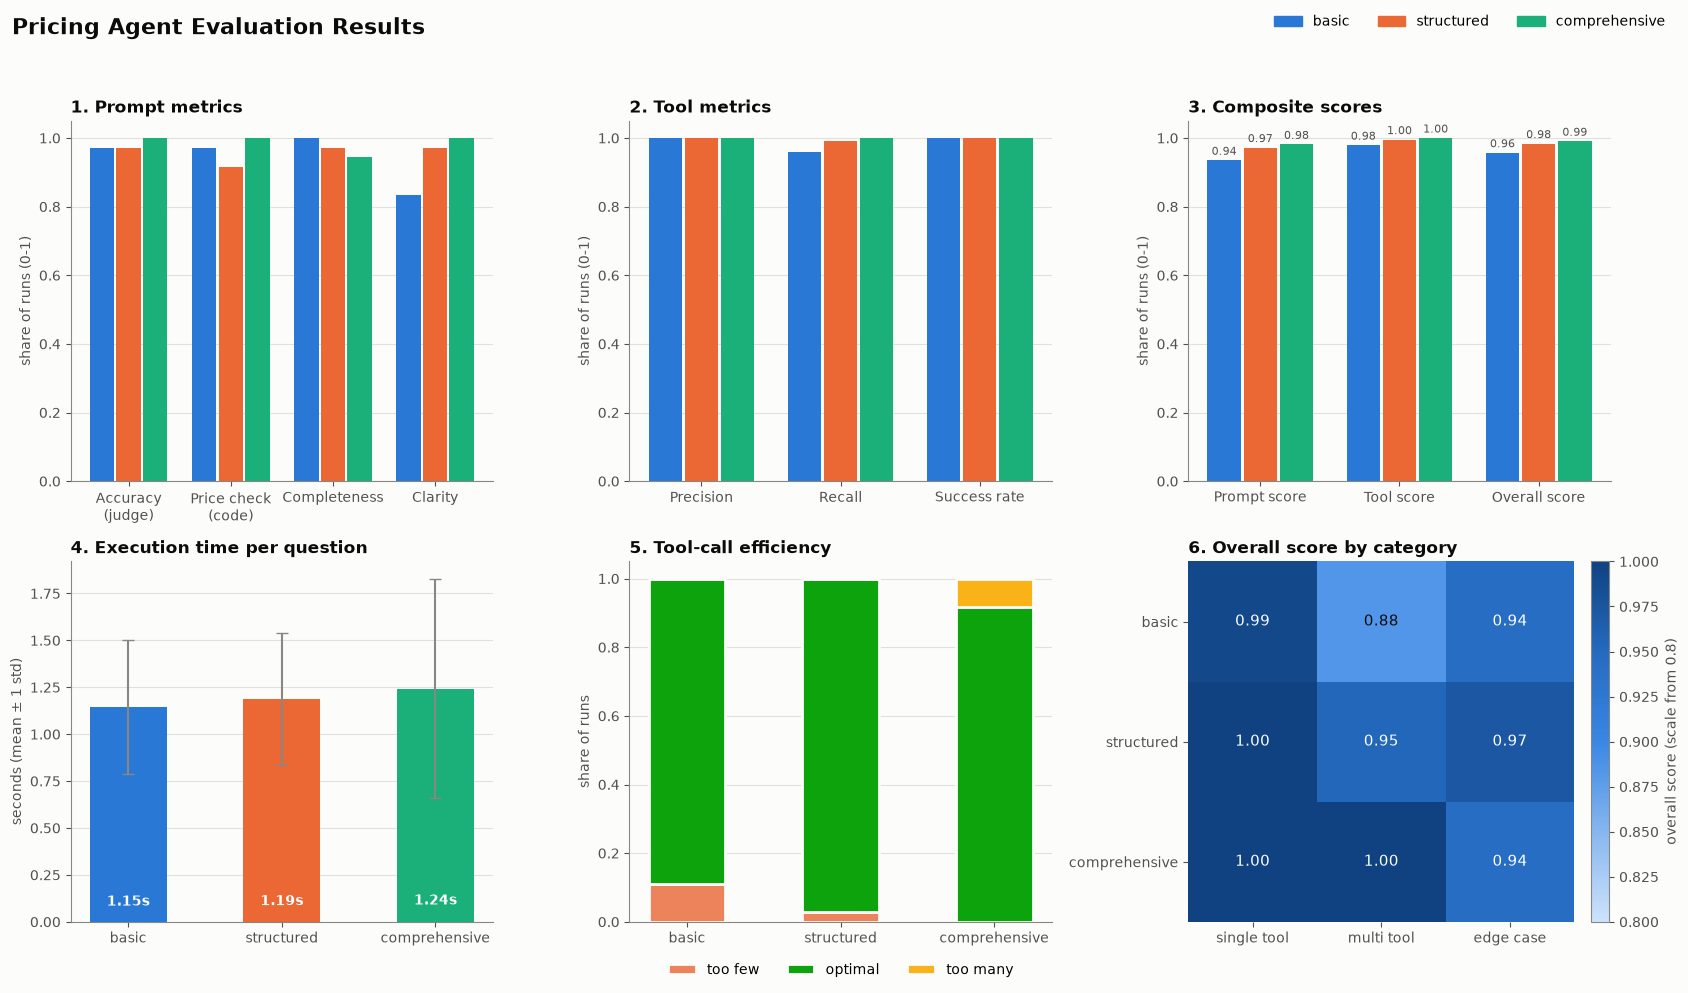

In [13]:
# Colours: one fixed colour per agent everywhere; status colours only for the efficiency states;
# a single-hue ramp for the heatmap. Thin bars, light solid gridlines, muted axes.
AGENT_COLORS = {"basic": "#2a78d6", "structured": "#eb6834", "comprehensive": "#1baf7a"}
EFFICIENCY_COLORS = {"too_few": "#ec835a", "optimal": "#0ca30c", "too_many": "#fab219"}
INK, INK_2, MUTED, GRID = "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
names = list(agents)

plt.rcParams.update({
    "font.family": "sans-serif", "font.size": 10, "axes.edgecolor": MUTED, "axes.labelcolor": INK_2,
    "axes.titlecolor": INK, "axes.titlesize": 12, "axes.titleweight": "bold", "xtick.color": INK_2,
    "ytick.color": INK_2, "axes.spines.top": False, "axes.spines.right": False,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})


def style(ax, ylabel=None, ylim=(0, 1.05)):
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    if ylim:
        ax.set_ylim(*ylim)
    if ylabel:
        ax.set_ylabel(ylabel)


def grouped_bars(ax, columns, labels, title, label_values=False):
    x = np.arange(len(columns))
    width = 0.26
    for i, name in enumerate(names):
        values = agent_summary.loc[name, columns].astype(float).values
        bars = ax.bar(x + (i - 1) * width, values, width * 0.92, color=AGENT_COLORS[name], label=name)
        if label_values:
            ax.bar_label(bars, labels=[f"{v:.2f}" for v in values], padding=2, fontsize=8, color=INK_2)
    ax.set_xticks(x, labels)
    ax.set_title(title, loc="left")
    style(ax, "share of runs (0-1)")


fig, axes = plt.subplots(2, 3, figsize=(17, 10))
fig.suptitle("Pricing Agent Evaluation Results", fontsize=16, fontweight="bold", color=INK, x=0.01, ha="left")

# Plot 1: Prompt metrics (judge) next to the code's price check
grouped_bars(axes[0, 0], ["accuracy", "price_in_range", "completeness", "clarity"],
             ["Accuracy\n(judge)", "Price check\n(code)", "Completeness", "Clarity"], "1. Prompt metrics")

# Plot 2: Tool metrics
grouped_bars(axes[0, 1], ["tool_precision", "tool_recall", "tool_success_rate"],
             ["Precision", "Recall", "Success rate"], "2. Tool metrics")

# Plot 3: Overall scores (only these bars carry value labels)
grouped_bars(axes[0, 2], ["prompt_score", "tool_score", "overall_score"],
             ["Prompt score", "Tool score", "Overall score"], "3. Composite scores", label_values=True)

# Plot 4: Execution time per question (mean, with one standard deviation)
ax = axes[1, 0]
means = evaluation_results.groupby("agent")["execution_time"].mean()[names]
stds = evaluation_results.groupby("agent")["execution_time"].std()[names]
ax.bar(names, means, width=0.5, color=[AGENT_COLORS[n] for n in names], yerr=stds, ecolor=MUTED, capsize=4)
for x, m in enumerate(means):
    ax.text(x, m * 0.06, f"{m:.2f}s", ha="center", va="bottom", fontsize=10, color="#ffffff", fontweight="bold")
ax.set_title("4. Execution time per question", loc="left")
style(ax, "seconds (mean ± 1 std)", ylim=None)

# Plot 5: Tool-call efficiency (share of runs with too few / the optimal number / too many calls)
ax = axes[1, 1]
eff = (evaluation_results.groupby("agent")["efficiency"].value_counts(normalize=True)
       .unstack(fill_value=0).reindex(index=names, columns=["too_few", "optimal", "too_many"], fill_value=0))
bottom = np.zeros(len(names))
for state in ["too_few", "optimal", "too_many"]:
    ax.bar(names, eff[state], width=0.5, bottom=bottom, color=EFFICIENCY_COLORS[state],
           label=state.replace("_", " "), edgecolor="#fcfcfb", linewidth=2)
    bottom += eff[state].values
ax.set_title("5. Tool-call efficiency", loc="left")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3, frameon=False)
style(ax, "share of runs")

# Plot 6: Overall score by question category (heatmap, one blue ramp from light to dark)
ax = axes[1, 2]
from matplotlib.colors import LinearSegmentedColormap
blues = LinearSegmentedColormap.from_list("blue_ramp", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281"])
vmin = min(0.8, np.floor(category_scores.values.min() * 10) / 10)  # all scores are high: start the scale near them
im = ax.imshow(category_scores.values, cmap=blues, vmin=vmin, vmax=1, aspect="auto")
ax.set_xticks(range(len(category_scores.columns)), [c.replace("_", " ") for c in category_scores.columns])
ax.set_yticks(range(len(names)), names)
for (r, c), v in np.ndenumerate(category_scores.values):
    ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=11,
            color="#ffffff" if (v - vmin) / (1 - vmin) > 0.5 else INK)
ax.set_title("6. Overall score by category", loc="left")
ax.spines[:].set_visible(False)
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=f"overall score (scale from {vmin:.1f})")

handles = [plt.Rectangle((0, 0), 1, 1, color=AGENT_COLORS[n]) for n in names]
fig.legend(handles, names, loc="upper right", ncol=3, frameon=False, bbox_to_anchor=(0.99, 0.995))
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

## 9. Cost analysis

In [14]:
# Illustrative cost rates, not a provider's price
# list: swap in your provider's current prices for real numbers. Token counts are the real ones the
# API reported (output includes the model's hidden reasoning tokens), not a characters / 4 estimate.
COST_PER_1K_INPUT = 0.0005
COST_PER_1K_OUTPUT = 0.001
COST_PER_TOOL_CALL = 0.001  # illustrative: the tools are local functions, so really ~$0


def estimate_cost(agent_results):
    """Estimate cost based on token usage"""
    costs = []
    for _, row in agent_results.iterrows():
        llm_cost = (row["input_tokens"] / 1000 * COST_PER_1K_INPUT
                    + row["output_tokens"] / 1000 * COST_PER_1K_OUTPUT)
        tool_cost = row["tool_count"] * COST_PER_TOOL_CALL
        costs.append(llm_cost + tool_cost)
    return costs


# Add cost column to results
evaluation_results["estimated_cost"] = estimate_cost(evaluation_results)

# Cost metrics per agent. A "successful task" is a run whose final price the judge marked accurate.
# The judge, not the code check, decides: it was validated in section 4b, and in section 7b it was right every
# time the two disagreed (re-check that after any new run before relying on it).
cost_summary = evaluation_results.groupby("agent").agg(
    total_cost=("estimated_cost", "sum"),
    avg_cost_per_task=("estimated_cost", "mean"),
    successful_tasks=("accuracy", "sum"),
    avg_llm_calls=("llm_calls", "mean"),
    avg_input_tokens=("input_tokens", "mean"),
    avg_output_tokens=("output_tokens", "mean"),
).loc[list(agents)]
cost_summary["cost_per_success"] = cost_summary["total_cost"] / cost_summary["successful_tasks"].replace(0, np.nan)

print("COST ANALYSIS (illustrative rates)")
print(cost_summary.round(5).to_string())
total_tokens = evaluation_results["input_tokens"].sum() + evaluation_results["output_tokens"].sum()
print(f"\nAgent tokens used in this evaluation: {total_tokens:,} (the judge calls are extra)")

COST ANALYSIS (illustrative rates)
               total_cost  avg_cost_per_task  successful_tasks  avg_llm_calls  avg_input_tokens  avg_output_tokens  cost_per_success
agent                                                                                                                               
basic             0.08053            0.00224                35        2.22222        1155.00000          437.22222           0.00230
structured        0.08246            0.00229                35        2.30556        1352.97222          308.38889           0.00236
comprehensive     0.10399            0.00289                36        2.41667        2098.30556          422.77778           0.00289

Agent tokens used in this evaluation: 207,888 (the judge calls are extra)


## 10. Recommendations

In [15]:
def generate_recommendations(agent_summary, cost_summary):
    """Generate recommendations based on evaluation results"""

    print("=" * 80)
    print("EVALUATION RECOMMENDATIONS")
    print("=" * 80)

    best = agent_summary["overall_score"].idxmax()
    cheapest = cost_summary["cost_per_success"].idxmin()
    fastest = agent_summary["execution_time"].idxmin()
    print(f"\n1. Best overall agent:        {best} (overall score {agent_summary.loc[best, 'overall_score']:.2f})")
    print(f"2. Most cost-effective agent: {cheapest} "
          f"(${cost_summary.loc[cheapest, 'cost_per_success']:.4f} per correct price)")
    print(f"3. Fastest agent:             {fastest} ({agent_summary.loc[fastest, 'execution_time']:.1f}s per question)")

    print("\nPer-agent notes:")
    for name, row in agent_summary.iterrows():
        notes = ["High accuracy" if row["accuracy"] >= 0.8 else f"Accuracy needs improvement ({row['accuracy']:.0%})"]
        if row["completeness"] < 0.7:
            notes.append(f"Completeness needs improvement ({row['completeness']:.0%})")
        if row["clarity"] < 0.7:
            notes.append(f"Clarity needs improvement ({row['clarity']:.0%})")
        if row["tool_recall"] < 0.7:
            notes.append(f"Missing expected tools (recall {row['tool_recall']:.0%})")
        if row["tool_precision"] < 0.8:
            notes.append(f"Calls tools it doesn't need (precision {row['tool_precision']:.0%})")
        checked = row[["accuracy", "completeness", "clarity", "tool_precision", "tool_recall"]].astype(float)
        notes.append(f"weakest metric: {checked.idxmin()} ({checked.min():.0%})")
        print(f"  - {name}: " + "; ".join(notes))

    best_score = agent_summary.loc[best, "overall_score"]
    print("\nDeployment recommendation:")
    if best_score >= 0.8:
        print(f"  Ready for production: '{best}' scores {best_score:.2f} (>= 0.8). "
              "Keep monitoring live answers with the judge and spot-check them by hand.")
    else:
        print(f"  Needs refinement: the best agent ('{best}') scores {best_score:.2f} (< 0.8).")


generate_recommendations(agent_summary, cost_summary)

EVALUATION RECOMMENDATIONS

1. Best overall agent:        comprehensive (overall score 0.99)
2. Most cost-effective agent: basic ($0.0023 per correct price)
3. Fastest agent:             basic (1.1s per question)

Per-agent notes:
  - basic: High accuracy; weakest metric: clarity (83%)
  - structured: High accuracy; weakest metric: accuracy (97%)
  - comprehensive: High accuracy; weakest metric: completeness (94%)

Deployment recommendation:
  Ready for production: 'comprehensive' scores 0.99 (>= 0.8). Keep monitoring live answers with the judge and spot-check them by hand.


## Summary per agent

In [16]:
# One summary per agent
best = agent_summary["overall_score"].idxmax()
cheapest = cost_summary["cost_per_success"].idxmin()


def best_for(name):
    if name == best:
        return "Production use"
    if name == cheapest:
        return "Cost-sensitive, high-volume use"
    if agent_summary.loc[name, "overall_score"] >= agent_summary.loc[best, "overall_score"] - 0.02:
        return "Close second at a lower cost" if (cost_summary.loc[name, "avg_cost_per_task"]
                                                 < cost_summary.loc[best, "avg_cost_per_task"]) else "Close second"
    return "Not recommended"


print("AGENT PERFORMANCE SUMMARY")
print("================================")
for name in agents:
    print(f"Agent: {name}")
    print(f"  Overall Score: {agent_summary.loc[name, 'overall_score']:.2f}")
    print(f"  Best for: {best_for(name)}")
    print(f"  Cost per task: ${cost_summary.loc[name, 'avg_cost_per_task']:.3f}")

AGENT PERFORMANCE SUMMARY
Agent: basic
  Overall Score: 0.96
  Best for: Cost-sensitive, high-volume use
  Cost per task: $0.002
Agent: structured
  Overall Score: 0.98
  Best for: Close second at a lower cost
  Cost per task: $0.002
Agent: comprehensive
  Overall Score: 0.99
  Best for: Production use
  Cost per task: $0.003


## Observations

**In one line:** all three agents do well (overall score 0.96 basic, 0.98 structured, 0.99 comprehensive), and the more detailed the prompt, the higher the score. The model (`gpt-oss-120b`) is strong and the tools do the arithmetic, so the prompt mostly changes *how* the agent answers, not *whether* it can.

**Where the prompt made a difference**
- **Clarity:** basic 83%, structured 97%, comprehensive 100%. The basic agent sometimes gave two options instead of one price (Q8: "$85.71 if the market is price-sensitive, otherwise..."). On Q11 it recommended $13.33 and then also offered a loss-making $10.45. The comprehensive prompt, which ends every answer with one `Recommended price: $X.XX` line, never had this problem.
- **Multi-tool questions:** basic scored 0.88 on them, the others 0.95 and 1.00. On Q10 the basic agent never called `competitor_matching` and worked the match price out itself. In one run it recommended $30.77, claiming the lowest price brings the most revenue. That is wrong, and the judge caught it.
- **Consistency:** reading the answers, the comprehensive agent gave the same price in all 3 runs of every question. Basic and structured each changed their price on one question (Q10). One structured run applied the 5% cut twice ($47.50 → $45.12). The same-price counts printed in section 7b use the code's extracted prices, so they inherit the code's 4 mistakes described below.

**Tool use:** no agent ever called a wrong tool (precision 100% for all three). Differences show up in recall (basic 96%, structured 99%, comprehensive 100%) and in call counts. Basic called too few tools in 4 runs; comprehensive called `competitor_matching` twice on Q10 (once to match, once to undercut). That counts as "too many" even though its answers were right. Tool metrics also miss some errors: the $45.12 answer called the right tools with a wrong starting price, so it scored 100% on tool use and failed only on accuracy.

**The judge:** it matched my labels on all 21 checks in section 4b (0 false passes), and the code's price check on 104 of 108 real answers. I read the 4 disagreements, and the judge was right every time. The code had picked the wrong number each time: the $60 cost instead of the $90.25 price, a rejected option ($55 or $10.45), or an earlier $47.50 when the agent's final (wrong) answer was $30.77. Simple text rules break easily on free-form answers, so the cost analysis counts a task as successful when the judge marks it accurate. The judge is the same model as the agents, so it could favour its own style; the hand-labelled set and the code cross-check are what make it trustworthy here.

**Cost and speed** (illustrative rates, real token counts): comprehensive costs about 29% more per task than basic ($0.0029 vs $0.0022), mostly because its long system prompt nearly doubles the input tokens (2,098 vs 1,155 per run). Basic is the cheapest per correct answer. At the illustrative $0.001 per tool call, tool calls are about half of every agent's cost; our tools are local functions, so in reality only the LLM part costs money. Every question took about 1.2 s on Cerebras, so speed doesn't separate the agents.

**Recommendation:** use the comprehensive prompt in production. It has the best score, the same price on every run, and an answer format that code can read. Keep checking live answers with the judge. Structured is a close second at about 20% lower cost per task. An easy win for any prompt is to ask for a final `Recommended price: $X` line.

**Limits:** 12 questions × 3 runs is a small sample, so a difference of one or two runs is within noise. The expected prices follow my own tool rules (5% undercut, 10% premium, 10% minimum margin, elasticity -2 / -1 / -0.5). Answers change between runs and between providers (this run used `gpt-oss-120b` on Cerebras).